# MODEL DEFINITION AND PARAMETER VALUE

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import brentq
from scipy.integrate import solve_ivp

# PARAMETERS
b = 3.80
a = 0.18
d = 0.15
alpha = 0.15

m1 = 0.12
e1 = 0.60
d1 = 0.12

m2 = 0.10
e2 = 0.50
gamma = 1.00
d2 = 0.14


# MODEL

def model(t, S):

    x, y, z = S

    dx = (
        b*x/(1 + alpha*y)
        - a*x**2
        - d*x
        - m1*x*y
    )

    dy = (
        e1*m1*x*y
        - d1*y
        - m2*y*z
    )

    dz = (
        e2*m2*y*z*(z/(gamma + z))
        - d2*z
    )

    return [dx, dy, dz]

# LOCAL STABILITY ANALISIS OF COEXISTENCE EQUILIBRIUM

In [7]:
# EQUILIBRIUM RELATIONS

def x_equilibrium(z):

    return (d1 + m2*z)/(e1*m1)


def y_equilibrium(z):

    return d2*(gamma + z)/(e2*m2*z)


# REDUCED EQUILIBRIUM EQUATION

def G(z):

    x = x_equilibrium(z)
    y = y_equilibrium(z)

    return (
        b/(1 + alpha*y)
        - a*x
        - d
        - m1*y
    )


# SEARCH POSITIVE ROOTS

z_grid = np.logspace(-4, 3, 20000)

roots = []

for i in range(len(z_grid) - 1):

    z1 = z_grid[i]
    z2 = z_grid[i + 1]

    if G(z1) * G(z2) < 0:

        root = brentq(G, z1, z2)

        if not roots or abs(root - roots[-1]) > 1e-6:

            roots.append(root)


# EQUILIBRIUM

equilibria = []

for z_star in roots:

    x_star = x_equilibrium(z_star)
    y_star = y_equilibrium(z_star)

    equilibria.append(
        np.array([
            x_star,
            y_star,
            z_star
        ])
    )


# JACOBIAN
def jacobian(E):

    x, y, z = E

    J = np.array([

        [
            b/(1 + alpha*y)
            - 2*a*x
            - d
            - m1*y,

            -b*alpha*x/(1 + alpha*y)**2
            - m1*x,

            0
        ],

        [
            e1*m1*y,

            e1*m1*x
            - d1
            - m2*z,

            -m2*y
        ],

        [
            0,

            e2*m2*z**2/(gamma + z),

            e2*m2*y*z
            * (2*gamma + z)
            / (gamma + z)**2
            - d2
        ]

    ])

    return J


# EQUILIBRIUM AND EIGENVALUE ANALYSIS

stable_equilibrium = None
stable_equilibrium_label = None

print(
    "COEXISTENCE EQUILIBRIUM"
)

for i, E in enumerate(equilibria):

    eigenvalues = np.linalg.eigvals(
        jacobian(E)
    )

    
    equilibrium_label = rf"E_{{4,{i+1}}}^*"

    print(
        f"\n{equilibrium_label}"
    )

    print(
        f"x* = {E[0]:.8f}"
    )

    print(
        f"y* = {E[1]:.8f}"
    )

    print(
        f"z* = {E[2]:.8f}"
    )

    print(
        "\nEigenvalues:"
    )

    for j, lam in enumerate(eigenvalues):

        print(
            f"lambda_{j+1} = "
            f"{lam.real:.8f}"
            f" {lam.imag:+.8f}i"
        )

    
    if np.all(eigenvalues.real < 0):

        if np.any(np.abs(eigenvalues.imag) > 1e-8):

            print(
                "Stability: Locally Asymptotically Stable "
                "(Stable Focus)"
            )

        else:

            print(
                "Stability: Locally Asymptotically Stable "
                "(Stable Node)"
            )

        stable_equilibrium = E.copy()

        stable_equilibrium_label = equilibrium_label

    elif np.any(eigenvalues.real > 0):

        print(
            "Stability: Unstable"
        )

    else:

        print(
            "Stability: Non-hyperbolic"
        )


# SELECT STABLE EQUILIBRIUM

if stable_equilibrium is None:

    raise ValueError(
        "No stable coexistence equilibrium was found."
    )


x_star, y_star, z_star = stable_equilibrium


print(
    "STABLE COEXISTENCE EQUILIBRIUM"
)

print(
    f"Equilibrium: {stable_equilibrium_label}"
)

print(
    f"x* = {x_star:.8f}"
)

print(
    f"y* = {y_star:.8f}"
)

print(
    f"z* = {z_star:.8f}"
)

COEXISTENCE EQUILIBRIUM

E_{4,1}^*
x* = 2.30691511
y* = 8.87403103
z* = 0.46097888

Eigenvalues:
lambda_1 = -0.20330231 +0.54061569i
lambda_2 = -0.20330231 -0.54061569i
lambda_3 = 0.08718606 +0.00000000i
Stability: Unstable

E_{4,2}^*
x* = 11.28881211
y* = 3.20416027
z* = 6.92794472

Eigenvalues:
lambda_1 = -1.32247438 +0.00000000i
lambda_2 = -0.34592637 +0.12707197i
lambda_3 = -0.34592637 -0.12707197i
Stability: Locally Asymptotically Stable (Stable Focus)
STABLE COEXISTENCE EQUILIBRIUM
Equilibrium: E_{4,2}^*
x* = 11.28881211
y* = 3.20416027
z* = 6.92794472


# TIME SERIES

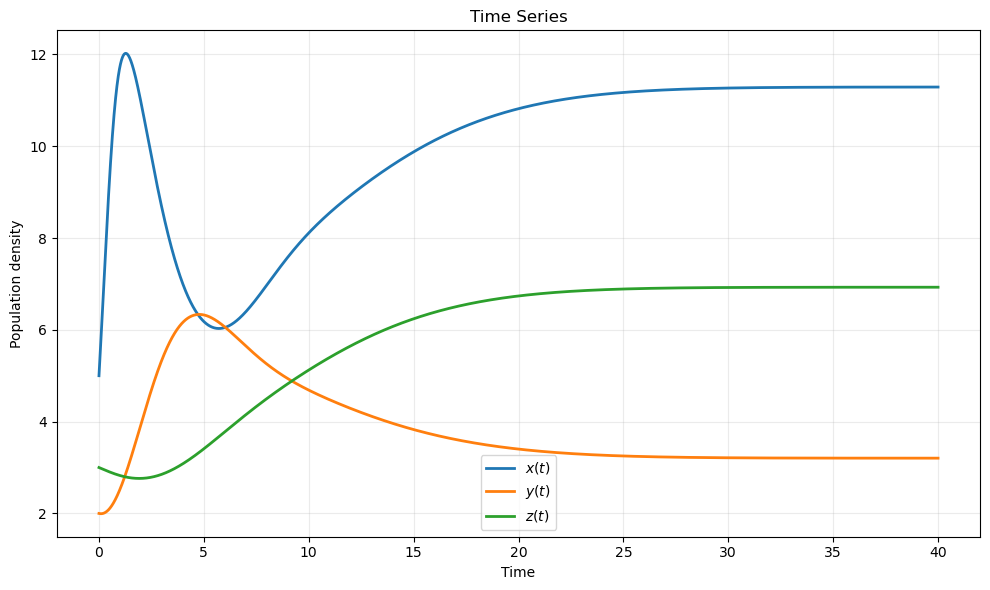

In [8]:
# TIME SERIES
# Initial condition
S0 = [
    5.0,
    2.0,
    3.0
]


# Time
t = np.linspace(
    0,
    40,
    5000
)


# Numerical solution
solution = solve_ivp(
    model,
    [0, 40],
    S0,
    t_eval=t,
    method='RK45',
    rtol=1e-9,
    atol=1e-11
)


# Extract solutions
x = solution.y[0]
y = solution.y[1]
z = solution.y[2]

# Plot
plt.figure(figsize=(10, 6))

plt.plot(
    solution.t,
    x,
    linewidth=2,
    label=r'$x(t)$'
)

plt.plot(
    solution.t,
    y,
    linewidth=2,
    label=r'$y(t)$'
)

plt.plot(
    solution.t,
    z,
    linewidth=2,
    label=r'$z(t)$'
)


plt.xlabel('Time')
plt.ylabel('Population density')

plt.title(
    'Time Series'
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()

# PHASE PORTRAIT

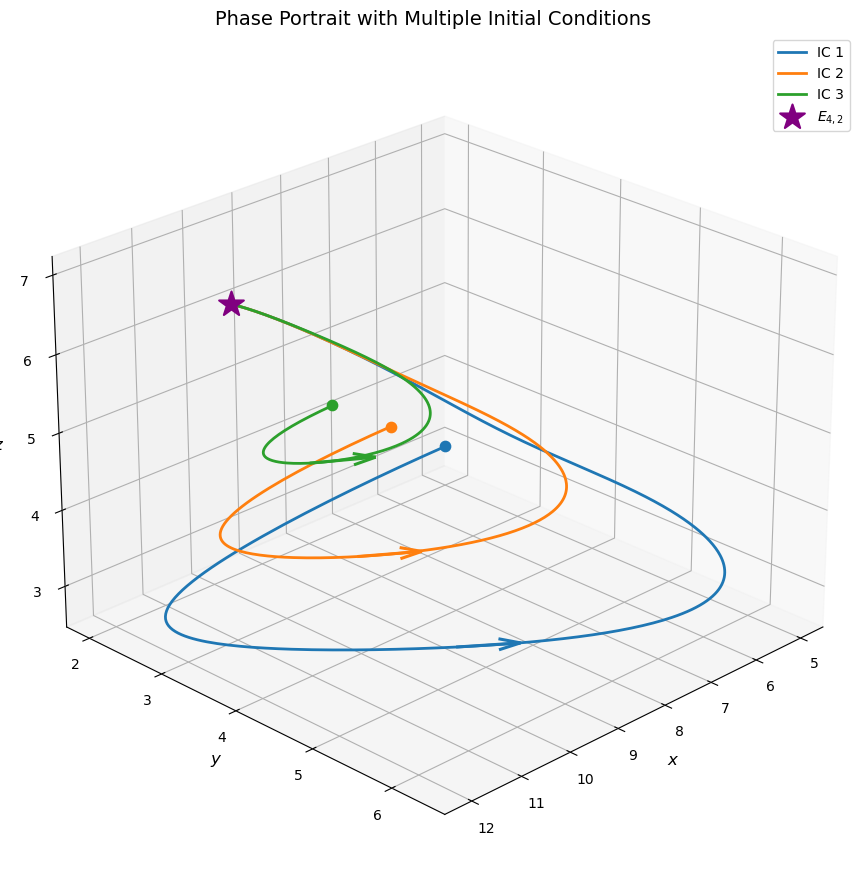

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

initial_conditions = [
    [5.0,  2.0, 3.0],
    [7.0,  2.5, 4.0],
    [9.0,  3.0, 5.0]
]


t_start = 0
t_end = 150

t_eval = np.linspace(
    t_start,
    t_end,
    5000
)

E_star = np.array([
    x_star,
    y_star,
    z_star
])

distance_threshold = 2.0


arrow_fraction = 0.15



arrow_length = 0.8




colors = plt.rcParams[
    'axes.prop_cycle'
].by_key()['color']




fig = plt.figure(
    figsize=(12, 9)
)

ax = fig.add_subplot(
    111,
    projection='3d'
)




for i, IC in enumerate(initial_conditions):


   

    solution = solve_ivp(
        model,
        [t_start, t_end],
        IC,
        t_eval=t_eval,
        method='RK45',
        rtol=1e-9,
        atol=1e-11
    )


    

    if not solution.success:

        print(
            f"Warning: simulation failed for IC {i+1}"
        )

        continue


    

    x = solution.y[0]
    y = solution.y[1]
    z = solution.y[2]


   
    color = colors[
        i % len(colors)
    ]


    
    ax.plot(
        x,
        y,
        z,
        color=color,
        linewidth=2.0,
        label=f'IC {i+1}'
    )


    
    ax.scatter(
        x[0],
        y[0],
        z[0],
        color=color,
        s=55,
        marker='o',
        depthshade=True
    )



    distance = np.sqrt(
        (x - x_star)**2
        + (y - y_star)**2
        + (z - z_star)**2
    )


   

    valid_indices = np.where(
        distance > distance_threshold
    )[0]




    valid_indices = valid_indices[
        valid_indices > 20
    ]


   

    if len(valid_indices) > 0:

        position = int(
            arrow_fraction
            * (len(valid_indices) - 1)
        )

        k = valid_indices[position]


        

        if k + 10 < len(x):


           

            dx = x[k + 10] - x[k]
            dy = y[k + 10] - y[k]
            dz = z[k + 10] - z[k]


            
            magnitude = np.sqrt(
                dx**2
                + dy**2
                + dz**2
            )


            if magnitude > 1e-12:

                dx = dx / magnitude
                dy = dy / magnitude
                dz = dz / magnitude


    
                ax.quiver(
                    x[k],
                    y[k],
                    z[k],

                    dx * arrow_length,
                    dy * arrow_length,
                    dz * arrow_length,

                    color=color,

                    linewidth=2.2,

                    arrow_length_ratio=0.35,

                    normalize=False
                )

ax.scatter(
    x_star,
    y_star,
    z_star,

    s=350,

    marker='*',

    color='purple',

    edgecolor='purple',

    linewidth=1.5,

    depthshade=False,

    label=r'$E_{4,2}$'
)

ax.set_xlabel(
    r'$x$',
    fontsize=12
)

ax.set_ylabel(
    r'$y$',
    fontsize=12
)

ax.set_zlabel(
    r'$z$',
    fontsize=12
)


ax.set_title(
    'Phase Portrait with Multiple Initial Conditions',
    fontsize=14
)


ax.legend(
    loc='best',
    fontsize=10
)


ax.view_init(
    elev=25,
    azim=45
)

ax.grid(True)

plt.tight_layout()

plt.show()